# Load libraries

In [1]:
import numpy as np
import itertools, pandas as pd
from models import LinearModel, ChoquetModel, LipschitzModel
from tests import (
    ZDT1, ZDT2, ZDT3, DTLZ1, DTLZ2,
    ZDT1_Shifted, ZDT2_Shifted, ZDT2_Combined,
    Kursawe, Fon, Sch1, Sch2,
    Ackley01, Schwefel04, Gulf,
    ExtendedProblem
)

import matplotlib.pyplot as plt
from utils import evaluate, visualise_weights

# Modelling

In [2]:
# ZDT calling
linear_model = LinearModel(problem = ZDT1(n_dim = 5), max_iter = 10, random_state = 42)
choquet_model = ChoquetModel(problem = ZDT1(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
slip_model = LipschitzModel(problem = ZDT1(n_dim = 5), max_iter = 10, random_state = 42,
                            type = "global_mon", num_k = 2) # ZDT3 is bi-objective

# # DTLZ calling
# linear_model = LinearModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42)
# choquet_model = ChoquetModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = DTLZ1(n_dim = 10, n_obj = 5), max_iter = 5, random_state = 42,
#                             type = "global_mon", num_k = 2)

In [3]:
# Self-constructed calling
# linear_model = LinearModel(problem = ZDT1_Shifted(n_dim = 5), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = ZDT1_Shifted(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = ZDT1_Shifted(n_dim = 5), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

# linear_model = LinearModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = ZDT2_Combined(n_dim = 10, order = [0, 1], C = 0.2), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

In [4]:
# extended_problem = ExtendedProblem(
#     problems = [Schwefel04(n_dim = 10), Gulf()],
#     order = None
# )

In [5]:
# linear_model = LinearModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = Sch1(n_dim = 5), max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

# linear_model = LinearModel(problem = extended_problem, max_iter = 10, random_state = 42)
# choquet_model = ChoquetModel(problem = extended_problem, max_iter = 10, random_state = 42, method = 2)
# slip_model = LipschitzModel(problem = extended_problem, max_iter = 10, random_state = 42,
#                             type = "global_mon", num_k = 2)

In [6]:
# Let them solve
linear_model.solve()
choquet_model.solve()
slip_model.solve()

# Summary their performance metrics

print(f"LinearModel :  PF {linear_model.PF.shape}  PS {linear_model.PS.shape}")
print(f"ChoquetModel:  PF {choquet_model.PF.shape} PS {choquet_model.PS.shape}")
print(f"LipschitzModel:  PF {slip_model.PF.shape} PS {slip_model.PS.shape}")
evaluate([linear_model, choquet_model, slip_model])

LinearModel :  PF (1807, 2)  PS (1807, 5)
ChoquetModel:  PF (1271, 2) PS (1271, 5)
LipschitzModel:  PF (1808, 2) PS (1808, 5)


,hypervolume,n_func_eval,n_non_dominated,n_iter,wallclock_time
LinearModel,0.664513,11193,1807,10,1.929219
ChoquetModel,0.662067,15639,1271,10,19.627034
LipschitzModel,0.660126,10653,1808,10,12.913394


# Model visualisation

In [7]:
# for kind in ["symmetric", "absolute", "norm"]:
#     visualise_weights(choquet_model, kind = kind);

In [8]:
# linear_model.visualise("true_pf");

## Linear Model

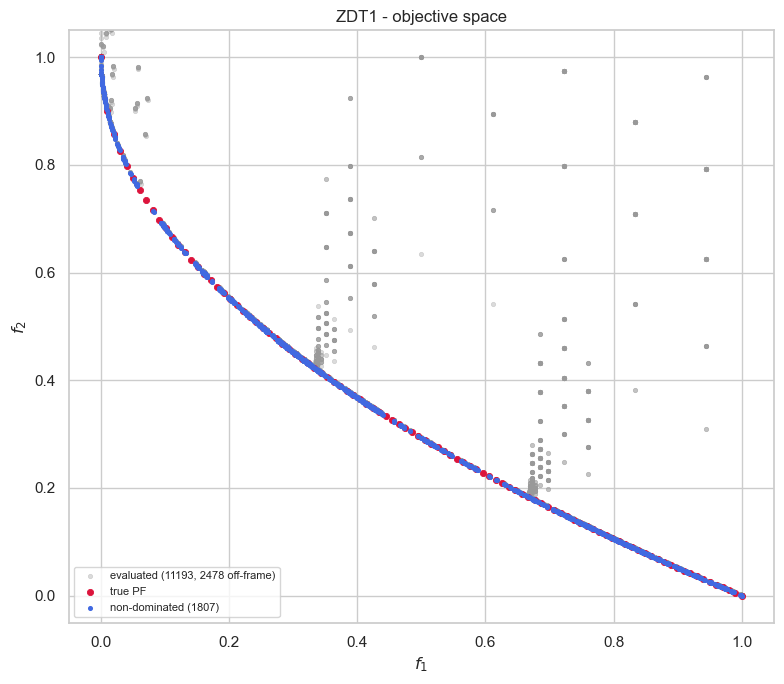

In [9]:
linear_model.visualise("objective");

In [10]:
linear_model.visualise("learning", show = False)

In [11]:
linear_model.visualise("learning", plot_scalarisation = True, show = False)

## Choquet Model

In [12]:
np.all((choquet_model.dec_hist >= 0) & (choquet_model.dec_hist <= 1))

np.True_

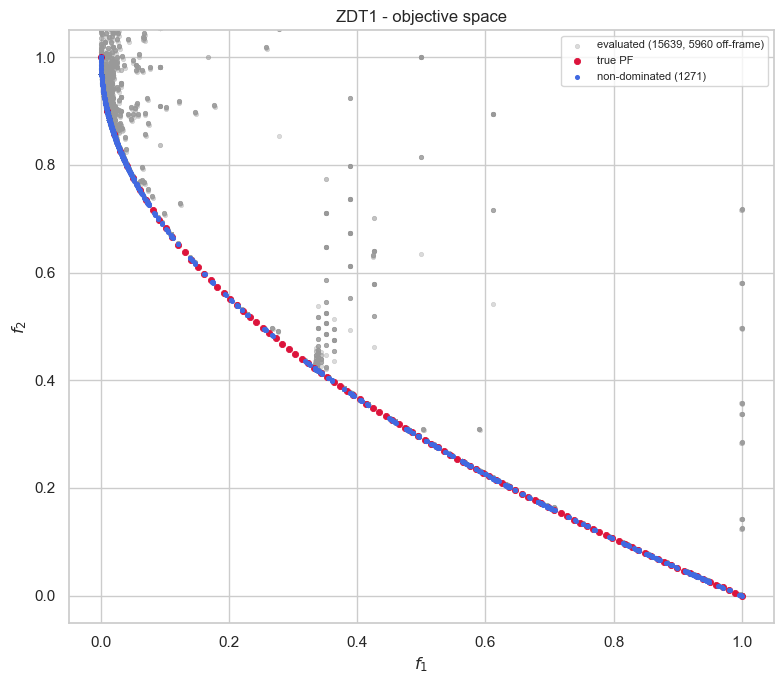

In [13]:
choquet_model.visualise("objective");

In [14]:
choquet_model.visualise("learning", show = False)

In [15]:
choquet_model.visualise("learning", plot_scalarisation = True, show = False)

## Lipschitz Model

In [16]:
np.all((slip_model.dec_hist >= 0) & (slip_model.dec_hist <= 1))

np.True_

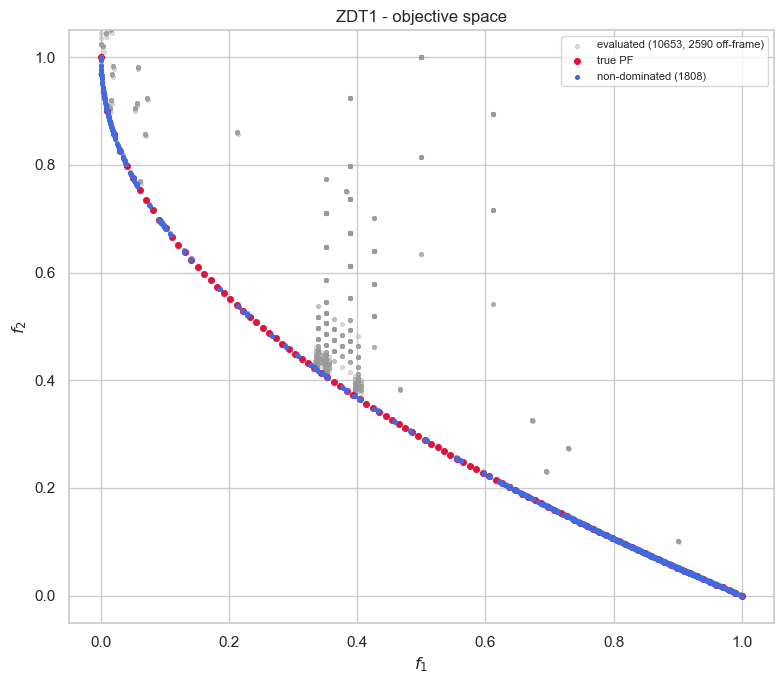

In [17]:
slip_model.visualise("objective");

In [18]:
slip_model.visualise("learning", show = False)

In [19]:
slip_model.visualise("learning", plot_scalarisation = True, show = False)

# Pareto Front and Pareto Set statistics

This section displays the statistics of the Pareto front and Pareto set found by the above-mentioned models. Note that, these are the set of non-dominated solutions, not all the iterates obtained throughout their runs.

In [20]:
import seaborn as sns


def plot_distributions(arrays, symbol, title):
    """Box plot and per-component ECDFs of each model's points; arrays maps model name -> (n_points, n_components)."""
    long = pd.concat(
        [pd.DataFrame(a).rename(columns = lambda k: f"${symbol}_{{{k + 1}}}$")
           .melt(var_name = "component", value_name = "value")
           .assign(model = f"{name} (n={len(a)})")
         for name, a in arrays.items()],
        ignore_index = True,
    )
    n_comp = long["component"].nunique()

    fig, ax = plt.subplots(figsize = (max(6, 1.6 * n_comp), 4))
    sns.boxplot(data = long, x = "component", y = "value", hue = "model", ax = ax,
                fliersize = 2, linewidth = 0.8)
    ax.set(xlabel = None, ylabel = f"${symbol}$", title = f"{title}: distribution per component")
    sns.move_legend(ax, "upper left", bbox_to_anchor = (1, 1), frameon = False)
    plt.show()

    g = sns.displot(long, x = "value", hue = "model", col = "component", kind = "ecdf",
                    col_wrap = min(n_comp, 5), height = 2.8, aspect = 1)
    g.set_titles("{col_name}")
    g.set_axis_labels(f"${symbol}$", "ECDF")
    g.figure.suptitle(f"{title}: empirical CDF per component", y = 1.04)
    plt.show()

## Pareto Front

In [21]:
# arr = {
#     "baseline": linear_model.PF,
#     "cas": choquet_model.PF,
#     "las": slip_model.PF
# }

arr = {
    "baseline": linear_model.obj_hist,
    "cas": choquet_model.obj_hist,
    "las": slip_model.obj_hist
}

df = pd.concat({name: pd.DataFrame(a) for name, a in arr.items()}, axis = 1)
df.columns.names = ["model", "k"]
df.describe()

model      baseline                         cas                         las  \
k                 0             1             0             1             0   
count  11193.000000  11193.000000  15639.000000  15639.000000  10653.000000   
mean       0.401261      1.095605      0.191780      1.510785      0.612909   
std        0.327335      1.362625      0.279474      1.305315      0.361586   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.118027      0.345791      0.009362      0.841104      0.335391   
50%        0.322370      0.520379      0.033751      0.986757      0.805242   
75%        0.695283      1.002250      0.333504      2.034372      0.918114   
max        1.000000      7.308882      1.000000      7.308882      1.000000   

model                
k                 1  
count  10653.000000  
mean       0.967152  
std        1.469283  
min        0.000000  
25%        0.042990  
50%        0.135113  
75%        1.002250  
max        7.308882

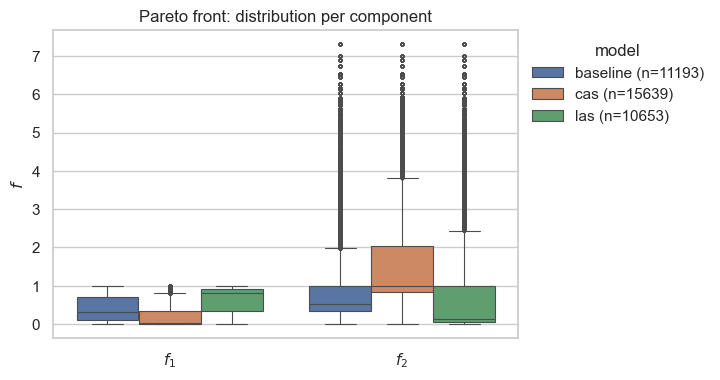

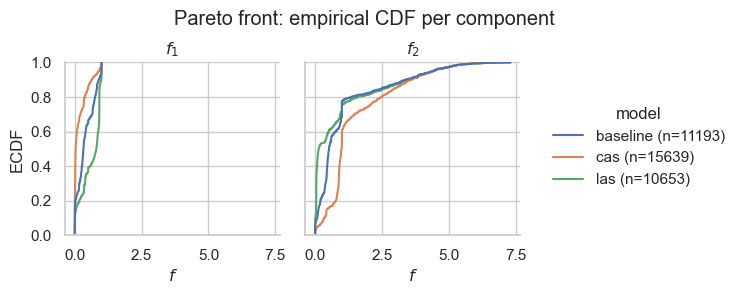

In [22]:
plot_distributions(arr, "f", "Pareto front")

## Pareto Set

In [23]:
# arr = {
#     "baseline": linear_model.PS,
#     "cas": choquet_model.PS,
#     "las": slip_model.PS
# }

arr = {
    "baseline": linear_model.dec_hist,
    "cas": choquet_model.dec_hist,
    "las": slip_model.dec_hist
}

df = pd.concat({name: pd.DataFrame(a) for name, a in arr.items()}, axis = 1)
df.columns.names = ["model", "k"]
df.describe()

model      baseline                                                          \
k                 0             1             2             3             4   
count  11193.000000  11193.000000  11193.000000  11193.000000  11193.000000   
mean       0.401261      0.088318      0.087838      0.084844      0.090311   
std        0.327335      0.208973      0.210441      0.204243      0.216431   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.118027      0.000000      0.000000      0.000000      0.000000   
50%        0.322370      0.000000      0.000000      0.000000      0.000000   
75%        0.695283      0.018519      0.017669      0.006173      0.010288   
max        1.000000      0.981205      0.999743      0.994368      0.999105   

model           cas                                                          \
k                 0             1             2             3             4   
count  15639.000000  15639.000000  15639.000000  15639.000000  15639.000000   
mean       0.191780      0.113815      0.102927      0.105996      0.110665   
std        0.279474      0.220770      0.212376      0.211806      0.221238   
min        0.000000      0.000000      0.000000      0.000000      0.000000   
25%        0.009362      0.000000      0.000000      0.000000      0.000000   
50%        0.033751      0.000000      0.000000      0.000000      0.000465   
75%        0.333504      0.114274      0.069396      0.088133      0.092593   
max        1.000000      0.981205      0.999743      0.994368      0.999105   

model           las                                                          
k                 0             1             2             3             4  
count  10653.000000  10653.000000  10653.000000  10653.000000  10653.000000  
mean       0.612909      0.092913      0.092240      0.089441      0.095543  
std        0.361586      0.213220      0.214754      0.208524      0.220955  
min        0.000000      0.000000      0.000000      0.000000      0.000000  
25%        0.335391      0.000000      0.000000      0.000000      0.000000  
50%        0.805242      0.000000      0.000000      0.000000      0.000000  
75%        0.918114      0.018519      0.018519      0.018519      0.018519  
max        1.000000      0.981205      0.999743      0.994368      0.999105

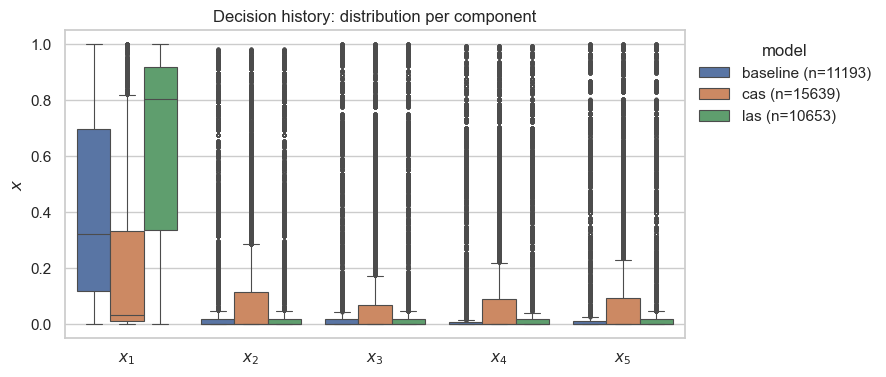

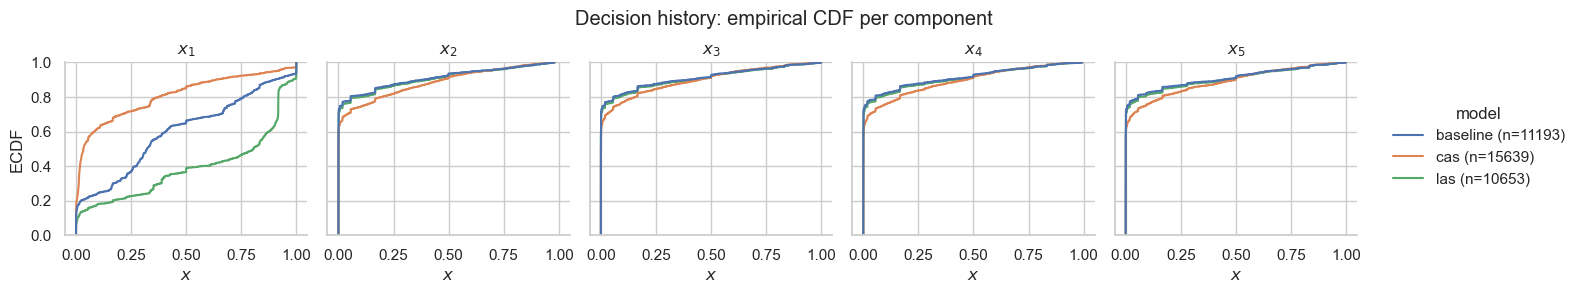

In [24]:
plot_distributions(arr, "x", "Decision history")

# Benchmark

Every configuration is solved by both models from the same seed, then scored by `evaluate()` against one shared reference point.

- **ZDT1/2/3** are 2-objective by construction, so they appear once per `n_dim` and ignore `obj_dims`.
- **DTLZ1/2** take `n_obj`, and are skipped when `n_dim <= n_obj` - there would be no tail variables left to carry `g`.
- Hypervolume is comparable **within** a row group only; the reference point differs between configurations, so never compare it across problems or dimensions.

In [25]:
# dec_dims   = [10, 20]
# obj_dims   = [2, 3, 4, 5]
# max_iter   = 50
# model_list = [LinearModel, ChoquetModel, LipschitzModel]
# prob_list  = [ZDT1, ZDT2, ZDT3, DTLZ1, DTLZ2]


# def build(problem, n_dim, n_obj):
#     """This grid cell's problem, or None if the combination does not exist: ZDT is 2-objective by
#        construction, and DTLZ needs n_dim > n_obj to leave tail variables to carry g."""
#     if problem in (ZDT1, ZDT2, ZDT3):
#         return problem(n_dim = n_dim) if n_obj == 2 else None
#     return problem(n_dim = n_dim, n_obj = n_obj) if n_dim > n_obj else None


# rows = []
# for problem, n_dim, n_obj in itertools.product(prob_list, dec_dims, obj_dims):
#     prob = build(problem, n_dim, n_obj)
#     if prob is None:
#         continue

#     fitted = [model(problem = prob, max_iter = max_iter, random_state = 42,
#                     **(dict(method = 2) if model is ChoquetModel else {}))
#               for model in model_list]
#     for m in fitted:
#         m.solve()

#     # evaluate() scores the pair against one shared reference point, and already times each solve
#     rows.append(evaluate(fitted).assign(problem = problem.__name__, n_dim = n_dim,
#                                         n_obj = prob.n_obj))
#     print(problem.__name__, f"n_dim={n_dim}", f"n_obj={prob.n_obj}",
#           dict(rows[-1]["wallclock_time"].round(1)))

# results = (pd.concat(rows).rename_axis("model").reset_index()
#              .set_index(["problem", "n_dim", "n_obj", "model"]).sort_index())
# results

In [26]:
# # hypervolume only compares within a configuration, so pick a winner per row
# hv = results["hypervolume"].unstack("model")
# hv.assign(winner = hv.idxmax(1), gap_pct = 100 * (hv.max(1) - hv.min(1)) / hv.max(1)).round(4)